## 1. Set Environment

In [1]:
%pip install rdkit

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, Crippen

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

RANDOM_STATE = 0
SPLIT_RANDOM_STATE = 0
TARGET = "exp"

FEATURES = [
    "MW",
    "TPSA",
    "HBD",
    "AromaticRings",
    "FractionCSP3",
    "RotatableBonds"
]

FEATURE_SETS = {
    "base": FEATURES.copy(),
    "plus_LogP": FEATURES + ["MolLogP"]
}

ALL_FEATURES = FEATURE_SETS["plus_LogP"]
EDA_COLUMNS = ALL_FEATURES + [TARGET]
GROUP_ORDER = ["≤500 Da", ">500 Da"]

OUTPUT_DIR = Path("final_project_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABELS = {
    "MW": "MW (Da)",
    "TPSA": "TPSA (Å²)",
    "HBD": "HBD (count)",
    "AromaticRings": "Aromatic rings (count)",
    "FractionCSP3": "Fraction Csp³ (dimensionless)",
    "RotatableBonds": "Rotatable bonds (count)",
    "MolLogP": "Calculated LogP (dimensionless)",
    TARGET: r"Experimental $\log D_{7.4}$ (dimensionless)"
}

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

## 2. Data Loading and Cleaning

In [3]:
url = (
    "https://deepchemdata.s3-us-west-1.amazonaws.com/"
    "datasets/Lipophilicity.csv"
)

df_orig = pd.read_csv(url)
df = df_orig.copy()

required_columns = ["CMPD_CHEMBLID", "smiles", TARGET]

assert set(required_columns).issubset(df.columns), (
    "Missing required columns."
)
assert df.index.is_unique

print("Original shape:", df.shape)
display(df.head())

print("\nMissing values:")
display(df.isna().sum())

print("\nData types:")
display(df.dtypes)

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate SMILES:", df["smiles"].duplicated().sum())

n_before = len(df)

# Clean target values
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df[TARGET] = df[TARGET].replace([np.inf, -np.inf], np.nan)

df = df.dropna(subset=["smiles", TARGET]).copy()
df["smiles"] = df["smiles"].astype(str).str.strip()
df = df.loc[df["smiles"].ne("")].copy()


def parse_smiles(smiles):
    try:
        return Chem.MolFromSmiles(smiles)
    except (TypeError, ValueError):
        return None


df["mol"] = df["smiles"].apply(parse_smiles)

invalid_count = df["mol"].isna().sum()
print("Invalid SMILES:", invalid_count)

# Remove invalid molecules before canonicalization
df = df.loc[df["mol"].notna()].copy()
df["canonical_smiles"] = df["mol"].apply(Chem.MolToSmiles)

duplicate_mask = df["canonical_smiles"].duplicated(keep=False)

print("Rows belonging to duplicate molecules:", duplicate_mask.sum())

if duplicate_mask.any():
    display(
        df.loc[
            duplicate_mask,
            ["CMPD_CHEMBLID", "canonical_smiles", TARGET]
        ].sort_values("canonical_smiles")
    )
    raise ValueError(
        "Review duplicate molecules before splitting the data."
    )

print("Removed rows:", n_before - len(df))
print("Cleaned shape:", df.shape)

Original shape: (4200, 3)


,CMPD_CHEMBLID,exp,smiles
0,CHEMBL596271,3.54,Cn1c(CN2CCN(CC2)c3ccc(Cl)cc3)nc4ccccc14
1,CHEMBL1951080,-1.18,COc1cc(OC)c(cc1NC(=O)CSCC(=O)O)S(=O)(=O)N2C(C)...
2,CHEMBL1771,3.69,COC(=O)[C@@H](N1CCc2sccc2C1)c3ccccc3Cl
3,CHEMBL234951,3.37,OC[C@H](O)CN1C(=O)C(Cc2ccccc12)NC(=O)c3cc4cc(C...
4,CHEMBL565079,3.10,Cc1cccc(C[C@H](NC(=O)c2cc(nn2C)C(C)(C)C)C(=O)N...



Missing values:


CMPD_CHEMBLID    0
exp              0
smiles           0
dtype: int64


Data types:


CMPD_CHEMBLID     object
exp              float64
smiles            object
dtype: object

Exact duplicate rows: 0
Duplicate SMILES: 0
Invalid SMILES: 0
Rows belonging to duplicate molecules: 0
Removed rows: 0
Cleaned shape: (4200, 5)


## 3. Molecular Descriptor Calculation

In [4]:
def calculate_descriptors(mol):
    return {
        "MW": Descriptors.MolWt(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": rdMolDescriptors.CalcNumHBD(mol),
        "AromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol),
        "RotatableBonds": rdMolDescriptors.CalcNumRotatableBonds(mol),
        "MolLogP": Crippen.MolLogP(mol)
    }


descriptor_df = pd.DataFrame(
    df["mol"].apply(calculate_descriptors).tolist(),
    index=df.index
)

# Safe to rerun: replace existing descriptor columns
df = df.drop(columns=ALL_FEATURES, errors="ignore")
df = df.join(descriptor_df)

assert df.columns.is_unique

for column in EDA_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="raise")

df[EDA_COLUMNS] = df[EDA_COLUMNS].replace(
    [np.inf, -np.inf], np.nan
)

assert df[TARGET].notna().all(), "Missing target values."
assert df["MW"].notna().all(), "Missing MW values."
assert df["MW"].gt(0).all(), "MW must be positive."

df["MW_group"] = np.where(
    df["MW"] <= 500,
    "≤500 Da",
    ">500 Da"
)

print("Missing values after descriptor calculation:")
display(df[EDA_COLUMNS].isna().sum())

display(df[["CMPD_CHEMBLID"] + ALL_FEATURES].head())

Missing values after descriptor calculation:


MW                0
TPSA              0
HBD               0
AromaticRings     0
FractionCSP3      0
RotatableBonds    0
MolLogP           0
exp               0
dtype: int64

,CMPD_CHEMBLID,MW,TPSA,HBD,AromaticRings,FractionCSP3,RotatableBonds,MolLogP
0,CHEMBL596271,340.858,24.30,0,3,0.315789,3,3.5489
1,CHEMBL1951080,494.591,122.24,2,2,0.363636,9,2.9901
2,CHEMBL1771,321.829,29.54,0,2,0.312500,3,3.6739
3,CHEMBL234951,419.890,105.66,4,3,0.263158,5,1.9237
4,CHEMBL565079,381.480,99.81,2,2,0.428571,6,2.0069


## 4. Development/Test Split and Cross-Validation Folds

In [5]:
# Split
df_train, df_temp = train_test_split(
    df,
    test_size=0.30,
    random_state=SPLIT_RANDOM_STATE
)

df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    random_state=SPLIT_RANDOM_STATE
)

dev_indices = df_train.index.union(df_val.index, sort=False)
test_indices = df_test.index.copy()

assert len(dev_indices.intersection(test_indices)) == 0
assert set(dev_indices).union(test_indices) == set(df.index)

data_final = df.copy()
data_final["split"] = "development"
data_final.loc[test_indices, "split"] = "test"

# Keep original row IDs for traceability
data_final["source_row"] = data_final.index

dev = data_final.loc[dev_indices].copy().reset_index(drop=True)
test = data_final.loc[test_indices].copy().reset_index(drop=True)

assert set(dev["canonical_smiles"]).isdisjoint(
    set(test["canonical_smiles"])
)

group_counts = dev["MW_group"].value_counts().reindex(
    GROUP_ORDER, fill_value=0
)
assert group_counts.min() >= 5

splitter = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

CV_SPLITS = list(
    splitter.split(dev[FEATURES], dev["MW_group"])
)

dev["cv_fold"] = -1
test["cv_fold"] = -1

for fold, (_, valid_positions) in enumerate(CV_SPLITS):
    dev.loc[valid_positions, "cv_fold"] = fold

assert dev["cv_fold"].ge(0).all()

shared_columns = [
    "source_row",
    "CMPD_CHEMBLID",
    "canonical_smiles",
    TARGET,
    *ALL_FEATURES,
    "MW_group",
    "split",
    "cv_fold"
]

shared_data = pd.concat(
    [dev[shared_columns], test[shared_columns]],
    ignore_index=True
)

shared_data.to_csv(
    OUTPUT_DIR / "shared_data_and_folds.csv",
    index=False
)

split_counts = pd.crosstab(
    shared_data["split"], shared_data["MW_group"]
).reindex(columns=GROUP_ORDER)

display(split_counts)
split_counts.to_csv(OUTPUT_DIR / "split_counts.csv")

print("Development:", len(dev))
print("Test:", len(test))

MW_group,≤500 Da,>500 Da
split,,
development,3145,425
test,561,69


Development: 3570
Test: 630


## 5. Exploratory Data Analysis

,variable,group,count,mean,std,min,25%,50%,75%,max,IQR
0,MW,All development,3570.0,382.795,107.535,113.160,306.289,388.371,456.586,1620.693,150.296
1,TPSA,All development,3570.0,78.641,32.208,0.000,56.032,79.800,98.517,702.020,42.485
2,HBD,All development,3570.0,1.618,1.178,0.000,1.000,1.000,2.000,22.000,1.000
3,AromaticRings,All development,3570.0,2.621,0.978,0.000,2.000,3.000,3.000,6.000,1.000
4,FractionCSP3,All development,3570.0,0.303,0.182,0.000,0.174,0.296,0.412,1.000,0.238
5,RotatableBonds,All development,3570.0,5.201,2.903,0.000,3.000,5.000,7.000,35.000,4.000
6,MolLogP,All development,3570.0,3.280,1.322,-5.622,2.435,3.278,4.122,10.343,1.687
7,exp,All development,3570.0,2.183,1.211,-1.500,1.400,2.350,3.100,4.500,1.700
8,MW,≤500 Da,3145.0,359.860,87.581,113.160,295.342,372.392,430.851,499.962,135.509
9,TPSA,≤500 Da,3145.0,74.937,28.141,0.000,53.170,76.440,94.830,170.830,41.660


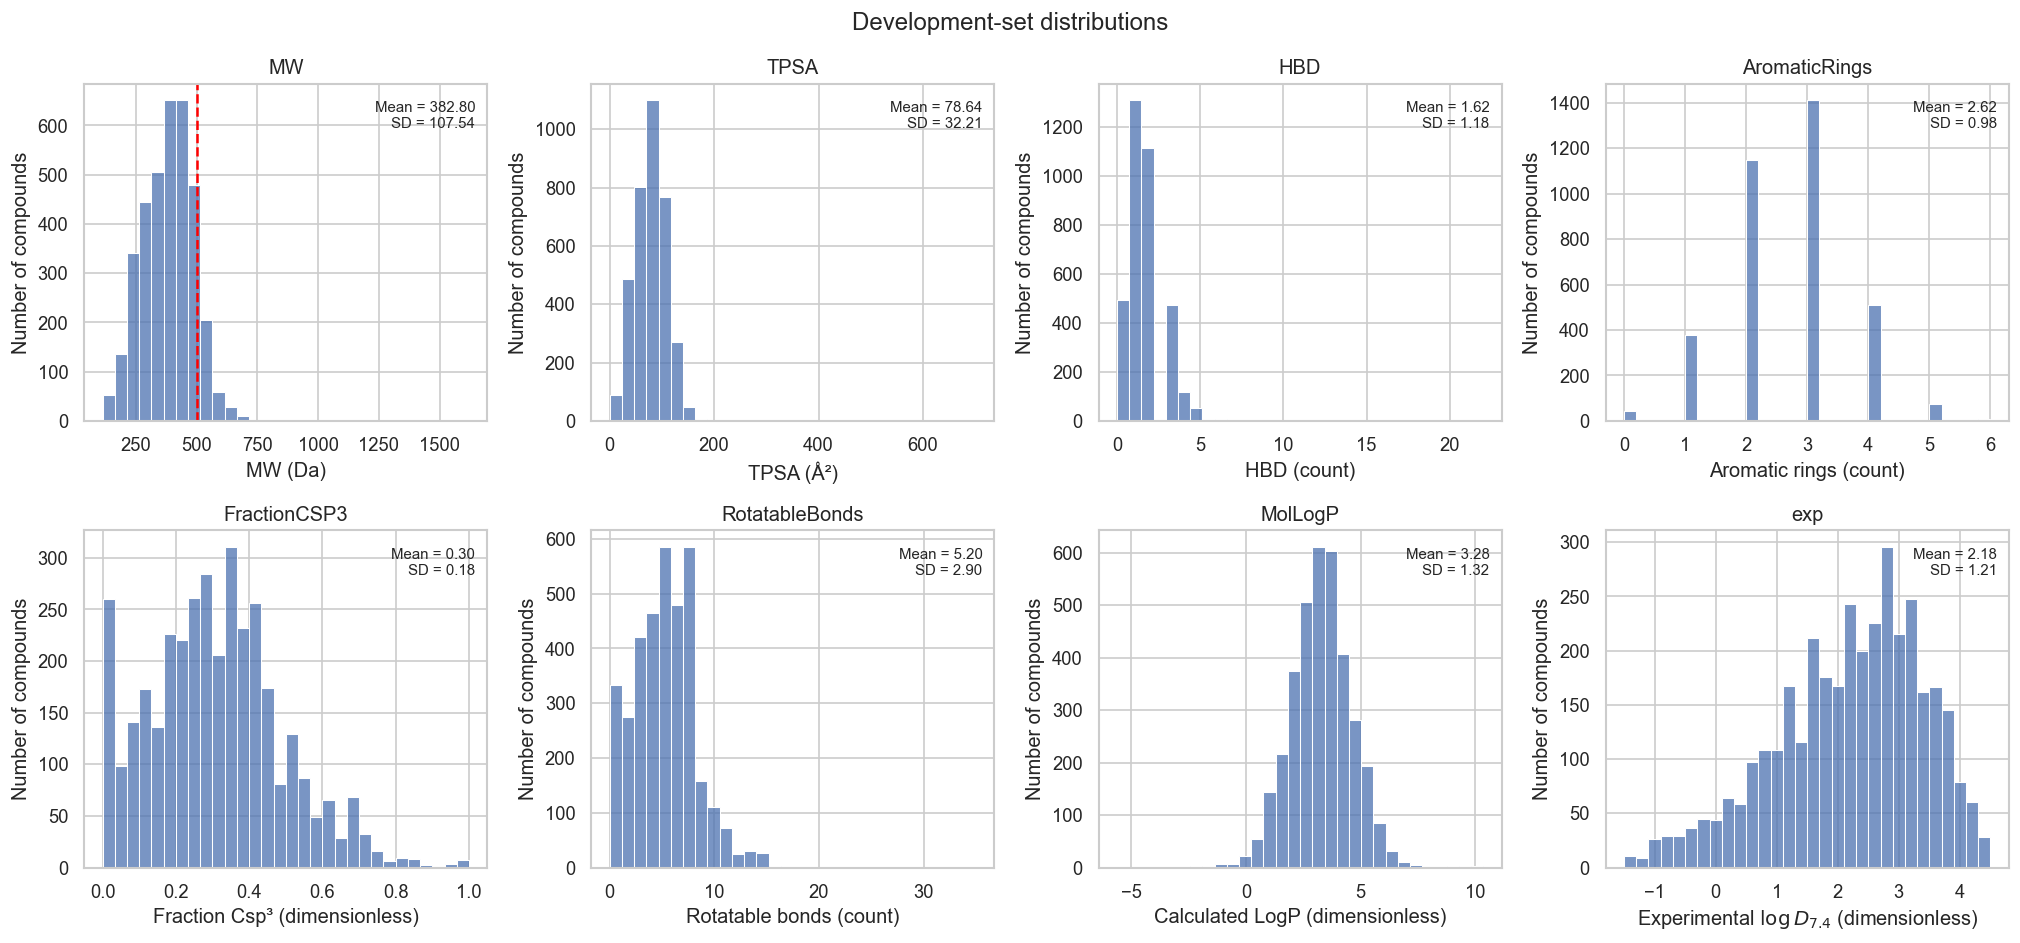

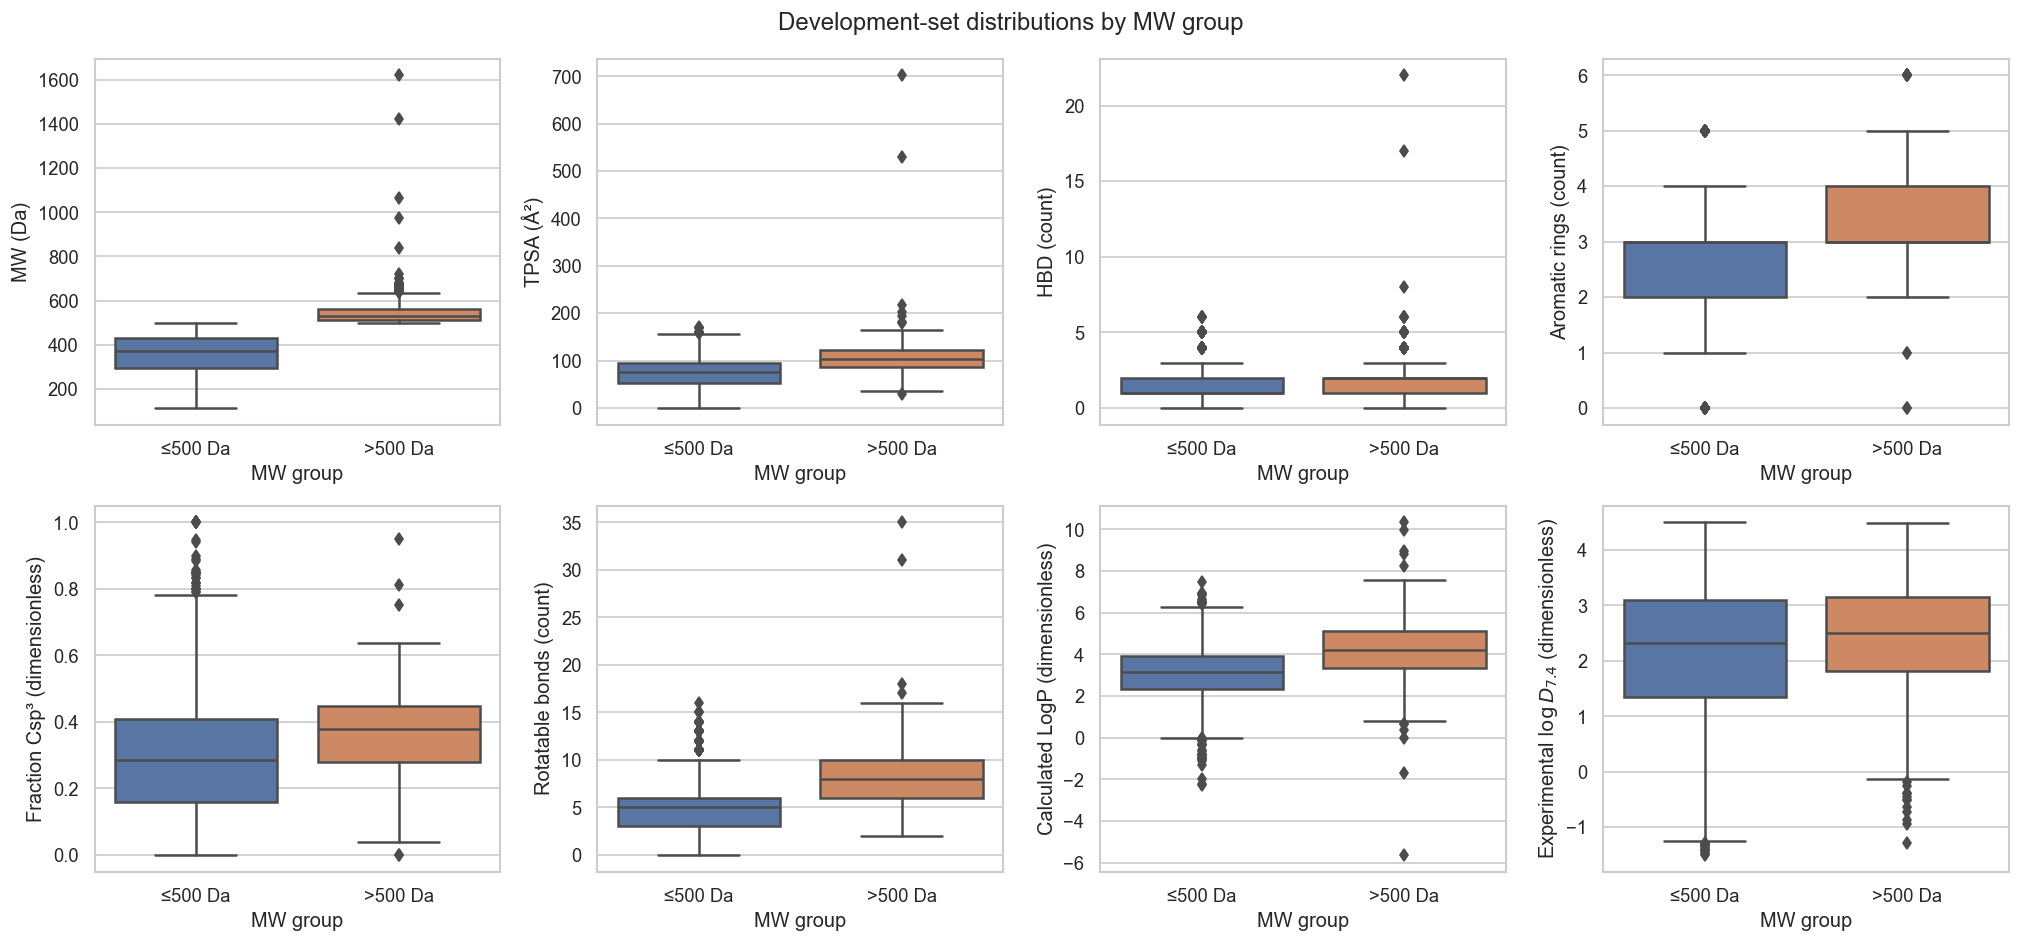

,variable,lower_fence,upper_fence,flagged_n,flagged_percent
0,MW,80.845,682.030,8,0.224
1,TPSA,-7.695,162.245,13,0.364
2,HBD,-0.500,3.500,180,5.042
3,AromaticRings,0.500,4.500,125,3.501
4,FractionCSP3,-0.183,0.769,36,1.008
5,RotatableBonds,-3.000,13.000,33,0.924
6,MolLogP,-0.096,6.653,41,1.148
7,exp,-1.150,5.650,19,0.532


,CMPD_CHEMBLID,canonical_smiles,MW,TPSA,HBD,AromaticRings,FractionCSP3,RotatableBonds,MolLogP,exp
1316,CHEMBL387675,CCCCCCCCCC(=O)N[C@@H](Cc1c[nH]c2ccccc12)C(=O)N...,1620.693,702.02,22,3,0.527778,35,-5.62180,-0.94
211,CHEMBL1200558,CC[C@H](C)[C@H](N)C1=N[C@H](C(=O)N[C@@H](CC(C)...,1422.720,530.87,17,2,0.636364,31,-1.67760,-0.46
3335,CHEMBL2170837,CCn1c(C)c(C(=O)O)c(-c2cccc(N3CCN(c4ccc(NS(=O)(...,1065.703,164.52,4,6,0.326923,18,10.34252,4.20
3137,CHEMBL443684,CC1(C)CCC(c2ccc(Cl)cc2)=C(CN2CCN(c3ccc(C(=O)NS...,974.634,128.36,2,4,0.425532,16,8.83320,0.64
896,CHEMBL1214185,CC[C@H]1OC(=O)[C@H](C)[C@@H](O[C@H]2C[C@@](C)(...,837.058,216.89,5,0,0.951220,13,2.20960,1.80
525,CHEMBL163,CC(C)c1nc(CN(C)C(=O)N[C@H](C(=O)N[C@@H](Cc2ccc...,720.962,145.78,4,4,0.432432,17,5.90520,4.30
1370,CHEMBL1094250,Cc1cc2c(C(=O)NC[C@H](C)c3ccccc3)c(O)c(O)cc2c(O...,700.788,179.58,8,6,0.190476,9,7.57744,3.48
979,CHEMBL74380,COC1/C=C/OC2(C)Oc3c(C)c(O)c4c(c3C2=O)C(=O)C=C(...,695.762,194.99,4,1,0.486486,2,3.63032,0.70


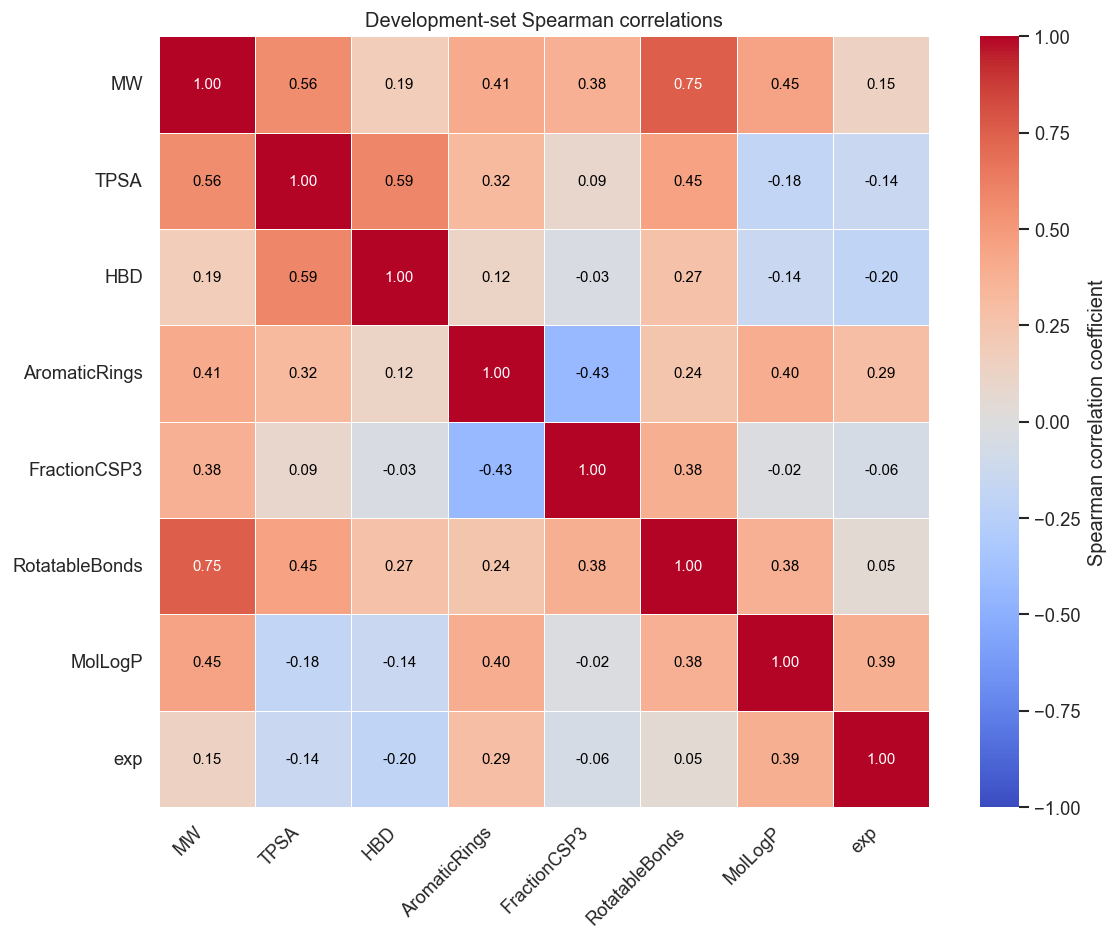

Highly correlated feature pairs:


MW  RotatableBonds    0.753121
Name: Spearman_rho, dtype: float64

HBD              -0.195353
TPSA             -0.144139
FractionCSP3     -0.061907
RotatableBonds    0.054477
MW                0.145178
AromaticRings     0.294264
MolLogP           0.388581
Name: exp, dtype: float64

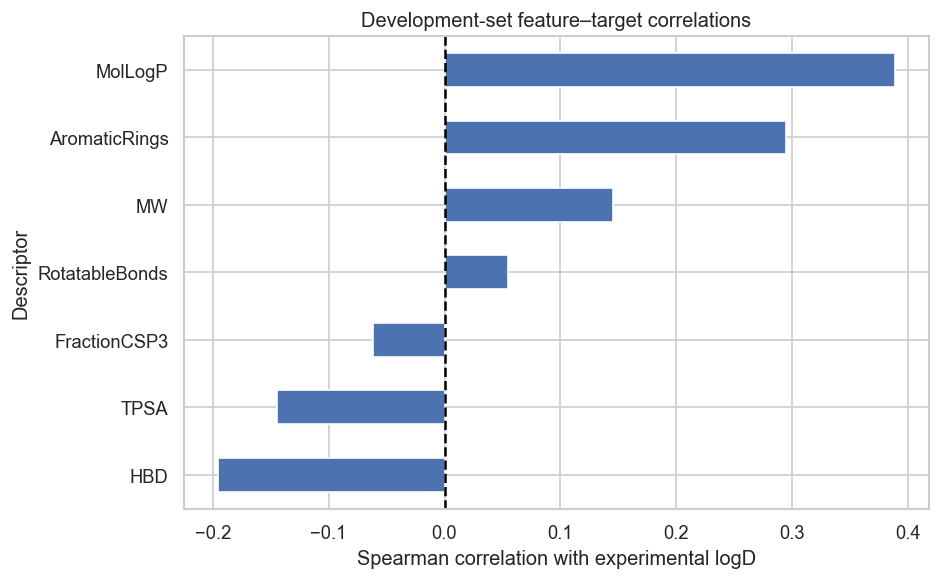

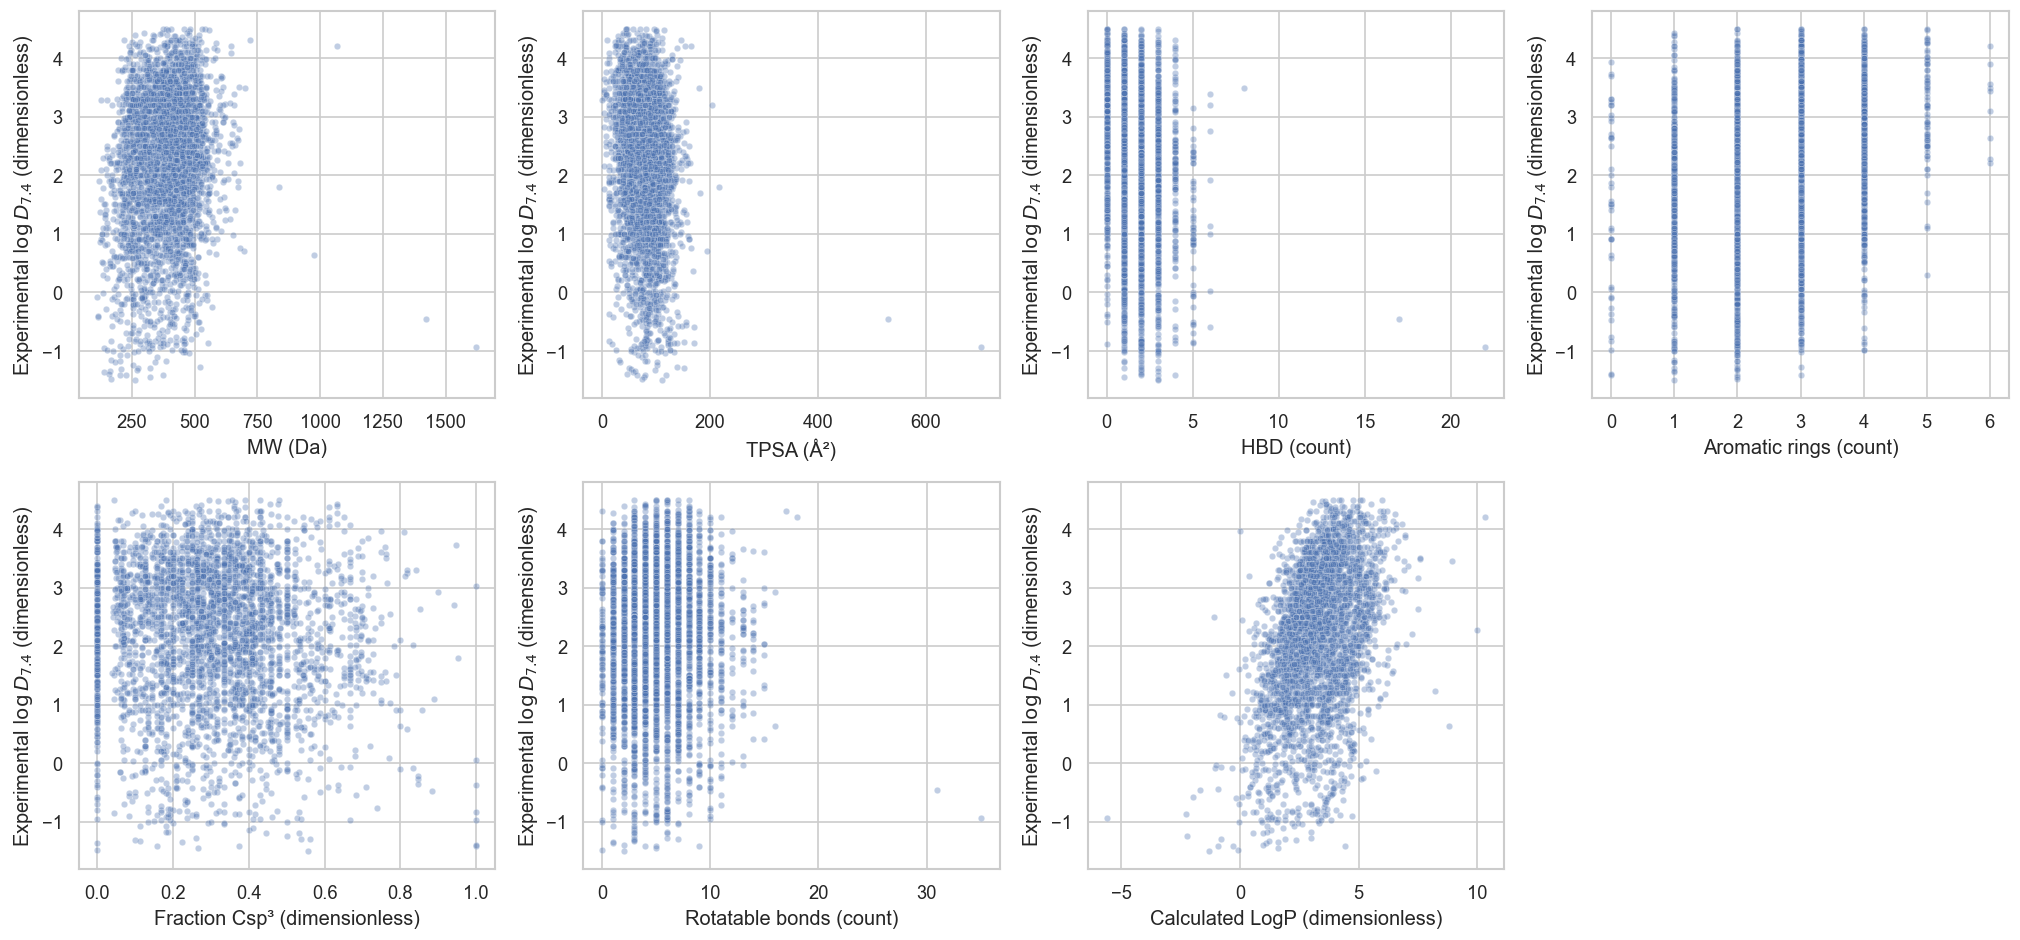

In [6]:
# Overall and group-specific summary statistics
summary_tables = []

groups = [
    ("All development", dev),
    *[(group, dev.loc[dev["MW_group"] == group])
      for group in GROUP_ORDER]
]

for group_name, group_data in groups:
    table = group_data[EDA_COLUMNS].describe().T
    table["IQR"] = table["75%"] - table["25%"]
    table.insert(0, "group", group_name)
    table.index.name = "variable"
    summary_tables.append(table.reset_index())

group_summary = pd.concat(summary_tables, ignore_index=True)
display(group_summary.round(3))

group_summary.to_csv(
    OUTPUT_DIR / "development_group_summary.csv",
    index=False
)


# Overall development distributions
fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for ax, column in zip(axes.flat, EDA_COLUMNS):
    sns.histplot(data=dev, x=column, bins=30, ax=ax)

    ax.set_xlabel(LABELS[column])
    ax.set_ylabel("Number of compounds")
    ax.set_title(column)

    ax.text(
        0.97, 0.95,
        f"Mean = {dev[column].mean():.2f}\n"
        f"SD = {dev[column].std():.2f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9
    )

    if column == "MW":
        ax.axvline(500, color="red", linestyle="--")

fig.suptitle("Development-set distributions")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "development_distributions.png")
plt.show()


# Distribution comparison between MW groups
fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for ax, column in zip(axes.flat, EDA_COLUMNS):
    sns.boxplot(
        data=dev,
        x="MW_group",
        y=column,
        order=GROUP_ORDER,
        ax=ax
    )
    ax.set_xlabel("MW group")
    ax.set_ylabel(LABELS[column])

fig.suptitle("Development-set distributions by MW group")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "group_distributions.png")
plt.show()


# IQR outlier flags: inspection only, no automatic removal
outlier_records = []

for column in EDA_COLUMNS:
    q1 = dev[column].quantile(0.25)
    q3 = dev[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    observed = dev[column].notna()
    flag = (dev[column] < lower) | (dev[column] > upper)

    outlier_records.append({
        "variable": column,
        "lower_fence": lower,
        "upper_fence": upper,
        "flagged_n": int(flag.sum()),
        "flagged_percent": (
            100 * flag[observed].mean() if observed.any() else np.nan
        )
    })

outlier_summary = pd.DataFrame(outlier_records)
display(outlier_summary.round(3))

outlier_summary.to_csv(
    OUTPUT_DIR / "outlier_summary.csv",
    index=False
)

mw_upper = outlier_summary.loc[
    outlier_summary["variable"] == "MW", "upper_fence"
].iloc[0]

mw_tail = dev.loc[
    dev["MW"] > mw_upper,
    ["CMPD_CHEMBLID", "canonical_smiles"] + EDA_COLUMNS
].sort_values("MW", ascending=False)

display(mw_tail)
mw_tail.to_csv(OUTPUT_DIR / "MW_tail_for_review.csv", index=False)


# Correlation heatmap: descriptors and target
corr_final = dev[EDA_COLUMNS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr_final,
    annot=False,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation coefficient"},
    ax=ax
)

for row in range(corr_final.shape[0]):
    for col in range(corr_final.shape[1]):
        value = corr_final.iloc[row, col]
        ax.text(
            col + 0.5,
            row + 0.5,
            f"{value:.2f}" if pd.notna(value) else "N/A",
            ha="center",
            va="center",
            color="white" if abs(value) >= 0.65 else "black",
            fontsize=9
        )

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_title("Development-set Spearman correlations")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "correlation_heatmap.png")
plt.show()

# Unique highly correlated feature pairs; exclude self-correlations
corr_features = dev[ALL_FEATURES].corr(method="spearman")
upper_mask = np.triu(
    np.ones(corr_features.shape, dtype=bool), k=1
)

high_corr_pairs = (
    corr_features.where(upper_mask)
    .stack()
    .rename("Spearman_rho")
)
high_corr_pairs = high_corr_pairs.loc[
    high_corr_pairs.abs() >= 0.75
]

print("Highly correlated feature pairs:")
display(high_corr_pairs)


# Feature-target correlations
corr_target = (
    corr_final[TARGET]
    .drop(TARGET)
    .sort_values()
)

display(corr_target)

fig, ax = plt.subplots(figsize=(8, 5))
corr_target.plot.barh(ax=ax)
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Spearman correlation with experimental logD")
ax.set_ylabel("Descriptor")
ax.set_title("Development-set feature–target correlations")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_target_correlations.png")
plt.show()


# Feature-target scatterplots
fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for ax, column in zip(axes.flat, ALL_FEATURES):
    sns.scatterplot(
        data=dev,
        x=column,
        y=TARGET,
        alpha=0.35,
        s=15,
        ax=ax
    )
    ax.set_xlabel(LABELS[column])
    ax.set_ylabel(LABELS[TARGET])

for ax in axes.flat[len(ALL_FEATURES):]:
    ax.set_visible(False)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_target_scatterplots.png")
plt.show()

## 6. Model Training and Hyperparameter Tuning

In [7]:
SCORING = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

RF_PARAMETERS = {
    "model__n_estimators": [200, 400, 600],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_features": [0.7, 1.0]
}

searches = {}
candidate_features = {}


def run_search(name, estimator, parameter_space, feature_columns):
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", estimator)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_space,
        n_iter=24 if parameter_space else 1,
        scoring=SCORING,
        refit="RMSE",
        cv=CV_SPLITS,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        return_train_score=True,
        error_score="raise"
    )

    search.fit(dev[feature_columns], dev[TARGET])

    searches[name] = search
    candidate_features[name] = feature_columns.copy()

    pd.DataFrame(search.cv_results_).to_csv(
        OUTPUT_DIR / f"{name}_cv_results.csv",
        index=False
    )

    joblib.dump(
        {
            "model": search.best_estimator_,
            "features": feature_columns.copy()
        },
        OUTPUT_DIR / f"{name}_model.joblib"
    )

    print(name)
    print("Best parameters:", search.best_params_)
    print("Best CV RMSE:", round(-search.best_score_, 4))
    print()


run_search(
    name="Dummy",
    estimator=DummyRegressor(strategy="mean"),
    parameter_space={},
    feature_columns=FEATURES
)

for feature_name, columns in FEATURE_SETS.items():
    run_search(
        name=f"RF_{feature_name}",
        estimator=RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        parameter_space=RF_PARAMETERS,
        feature_columns=columns
    )

Dummy
Best parameters: {}
Best CV RMSE: 1.211

RF_base
Best parameters: {'model__n_estimators': 600, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': None}
Best CV RMSE: 0.9213

RF_plus_LogP
Best parameters: {'model__n_estimators': 600, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': None}
Best CV RMSE: 0.8881



## 7. Cross-Validation Comparison and Model Selection

In [8]:
comparison_rows = []

for name, search in searches.items():
    i = search.best_index_
    results = search.cv_results_

    comparison_rows.append({
        "model": name,
        "train_RMSE": -results["mean_train_RMSE"][i],
        "CV_RMSE": -results["mean_test_RMSE"][i],
        "CV_RMSE_SD": results["std_test_RMSE"][i],
        "train_MAE": -results["mean_train_MAE"][i],
        "CV_MAE": -results["mean_test_MAE"][i],
        "train_R2": results["mean_train_R2"][i],
        "CV_R2": results["mean_test_R2"][i],
        "best_parameters": str(search.best_params_)
    })

cv_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("CV_RMSE")
    .reset_index(drop=True)
)

display(cv_comparison.round(4))

cv_comparison.to_csv(
    OUTPUT_DIR / "CV_model_comparison.csv",
    index=False
)

rf_results = cv_comparison.set_index("model")

logp_improvement = (
    rf_results.loc["RF_base", "CV_RMSE"]
    - rf_results.loc["RF_plus_LogP", "CV_RMSE"]
)

print(
    "CV RMSE improvement after adding LogP:",
    round(logp_improvement, 4)
)
print("Positive values indicate lower RMSE with LogP.")

# Negative RMSE: larger best_score_ is better.
my_best_rf = max(
    ["RF_base", "RF_plus_LogP"],
    key=lambda name: searches[name].best_score_
)

selected_name = my_best_rf

print("\nRF configuration selected using CV:", selected_name)

,model,train_RMSE,CV_RMSE,CV_RMSE_SD,train_MAE,CV_MAE,train_R2,CV_R2,best_parameters
0,RF_plus_LogP,0.3371,0.8881,0.0244,0.2564,0.6735,0.9224,0.4604,"{'model__n_estimators': 600, 'model__min_sampl..."
1,RF_base,0.3510,0.9213,0.0131,0.2681,0.7007,0.9159,0.4187,"{'model__n_estimators': 600, 'model__min_sampl..."
2,Dummy,1.2104,1.2110,0.0229,0.9826,0.9832,0.0000,-0.0033,{}


CV RMSE improvement after adding LogP: 0.0332
Positive values indicate lower RMSE with LogP.

RF configuration selected using CV: RF_plus_LogP


## 8. Final Test Evaluation and Molecular-Weight Group Analysis

In [9]:
MY_MODELS = ["Dummy", "RF_base", "RF_plus_LogP"]

my_test_predictions = {}
metric_rows = []

for name in MY_MODELS:
    feature_columns = candidate_features[name]
    fitted_model = searches[name].best_estimator_

    y_pred = fitted_model.predict(test[feature_columns])

    predictions = test[
        ["source_row", "CMPD_CHEMBLID", "MW", "MW_group"]
    ].copy()

    predictions["y_true"] = test[TARGET].to_numpy()
    predictions["y_pred"] = y_pred
    predictions["residual"] = (
        predictions["y_true"] - predictions["y_pred"]
    )
    predictions["absolute_error"] = predictions["residual"].abs()

    my_test_predictions[name] = predictions

    predictions.to_csv(
        OUTPUT_DIR / f"{name}_test_predictions.csv",
        index=False
    )

    evaluation_groups = [
        ("All test", predictions),
        *[
            (
                group,
                predictions.loc[predictions["MW_group"] == group]
            )
            for group in GROUP_ORDER
        ]
    ]

    for group_name, group_data in evaluation_groups:
        if group_data.empty:
            continue

        y_true = group_data["y_true"]
        y_hat = group_data["y_pred"]

        metric_rows.append({
            "model": name,
            "group": group_name,
            "n": len(group_data),
            "MAE": mean_absolute_error(y_true, y_hat),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_hat)),
            "R2": (
                r2_score(y_true, y_hat)
                if len(group_data) >= 2 and y_true.nunique() > 1
                else np.nan
            )
        })

my_test_metrics = pd.DataFrame(metric_rows)

overall_test = (
    my_test_metrics.loc[my_test_metrics["group"] == "All test"]
    .set_index("model")
    .loc[MY_MODELS, ["n", "MAE", "RMSE", "R2"]]
)

group_test = my_test_metrics.loc[
    my_test_metrics["group"] != "All test"
].copy()

print("Overall test results:")
display(overall_test.round(4))

print("Test results by MW group:")
display(group_test.round(4))

my_test_metrics.to_csv(
    OUTPUT_DIR / "my_models_test_metrics.csv",
    index=False
)

selected_predictions = my_test_predictions[selected_name]


# Bootstrap CI for the selected RF's group MAE difference.
# Difference = MAE (>500 Da) - MAE (≤500 Da).
low_errors = selected_predictions.loc[
    selected_predictions["MW_group"] == "≤500 Da",
    "absolute_error"
].to_numpy()

high_errors = selected_predictions.loc[
    selected_predictions["MW_group"] == ">500 Da",
    "absolute_error"
].to_numpy()

assert len(low_errors) >= 2 and len(high_errors) >= 2

rng = np.random.default_rng(RANDOM_STATE)
n_bootstrap = 10000
bootstrap_differences = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    low_sample = rng.choice(
        low_errors, size=len(low_errors), replace=True
    )
    high_sample = rng.choice(
        high_errors, size=len(high_errors), replace=True
    )

    bootstrap_differences[i] = (
        high_sample.mean() - low_sample.mean()
    )

observed_difference = high_errors.mean() - low_errors.mean()
ci_lower, ci_upper = np.quantile(
    bootstrap_differences, [0.025, 0.975]
)

group_comparison = pd.DataFrame([{
    "model": selected_name,
    "n_low_MW": len(low_errors),
    "n_high_MW": len(high_errors),
    "MAE_low_MW": low_errors.mean(),
    "MAE_high_MW": high_errors.mean(),
    "MAE_difference_high_minus_low": observed_difference,
    "CI_95_lower": ci_lower,
    "CI_95_upper": ci_upper
}])

print("\nMW-group MAE comparison for the CV-selected RF:")
display(group_comparison.round(4))

group_comparison.to_csv(
    OUTPUT_DIR / "MW_group_MAE_bootstrap.csv",
    index=False
)

print("Difference = MAE (>500 Da) - MAE (≤500 Da)")
print("Positive: larger absolute errors in the >500 Da group.")
print("Negative: smaller absolute errors in the >500 Da group.")

if ci_lower <= 0 <= ci_upper:
    print(
        "The 95% bootstrap CI includes zero; "
        "the direction of the group MAE difference is uncertain."
    )
else:
    print(
        "The 95% bootstrap CI excludes zero; "
        "the estimated group MAE difference has a consistent direction."
    )

print("\nResults saved to:", OUTPUT_DIR.resolve())

Overall test results:


,n,MAE,RMSE,R2
model,,,,
Dummy,630,0.9271,1.1585,-0.0004
RF_base,630,0.6731,0.8788,0.4243
RF_plus_LogP,630,0.6329,0.8253,0.4924


Test results by MW group:


,model,group,n,MAE,RMSE,R2
1,Dummy,≤500 Da,561,0.9414,1.1780,-0.0002
2,Dummy,>500 Da,69,0.8106,0.9865,-0.1329
4,RF_base,≤500 Da,561,0.6829,0.8887,0.4308
5,RF_base,>500 Da,69,0.5941,0.7944,0.2653
7,RF_plus_LogP,≤500 Da,561,0.6402,0.8321,0.5009
8,RF_plus_LogP,>500 Da,69,0.5740,0.7671,0.3149



MW-group MAE comparison for the CV-selected RF:


,model,n_low_MW,n_high_MW,MAE_low_MW,MAE_high_MW,MAE_difference_high_minus_low,CI_95_lower,CI_95_upper
0,RF_plus_LogP,561,69,0.6402,0.574,-0.0661,-0.1902,0.0631


Difference = MAE (>500 Da) - MAE (≤500 Da)
Positive: larger absolute errors in the >500 Da group.
Negative: smaller absolute errors in the >500 Da group.
The 95% bootstrap CI includes zero; the direction of the group MAE difference is uncertain.

Results saved to: /Users/helenliu/Downloads/final_project_results
